In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

In [82]:
filename1 = Path("../data/raw/O-Net/software_skills.csv")
dfSoftwareSkills = pd.read_csv(filename1, header=0)

In [83]:
dfSoftwareSkills.head()

,O*NET-SOC Code,Title,Workplace Example,Element ID,Element Name,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,2.E.5.b,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,2.E.6.f,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,2.E.5.a,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,2.E.6.c,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,2.E.2.a,Accounting software,N,N


In [84]:
filename2 = Path("../data/raw/O-Net/transferable_skills.csv")
dfTransferableSkills = pd.read_csv(filename2, header=0)

In [85]:
dfTransferableSkills.head()

,O*NET-SOC Code,Title,Element ID,Element Name,Scale ID,Scale Name,Data Value,N,Standard Error,Lower CI Bound,Upper CI Bound,Recommend Suppress,Not Relevant,Date,Domain Source
0,11-1011.00,Chief Executives,2.B.1.a,Social Perceptiveness,IM,Importance,4.12,8,0.1250,3.8800,4.3700,N,NaN,08/2023,Analyst
1,11-1011.00,Chief Executives,2.B.1.a,Social Perceptiveness,LV,Level,4.25,8,0.1637,3.9292,4.5708,N,N,08/2023,Analyst
2,11-1011.00,Chief Executives,2.B.1.b,Coordination,IM,Importance,4.25,8,0.1637,3.9292,4.5708,N,NaN,08/2023,Analyst
3,11-1011.00,Chief Executives,2.B.1.b,Coordination,LV,Level,4.88,8,0.2266,4.4309,5.3191,N,N,08/2023,Analyst
4,11-1011.00,Chief Executives,2.B.1.c,Persuasion,IM,Importance,4.00,8,0.1890,3.6296,4.3704,N,NaN,08/2023,Analyst


# Check for missing values

In [86]:
nan_count= np.sum(dfSoftwareSkills.isnull(), axis=0)
nan_count

O*NET-SOC Code       0
Title                0
Workplace Example    0
Element ID           0
Element Name         0
Hot Technology       0
In Demand            0
dtype: int64

In [87]:
nan_count= np.sum(dfTransferableSkills.isnull(), axis=0)
nan_count

O*NET-SOC Code            0
Title                     0
Element ID                0
Element Name              0
Scale ID                  0
Scale Name                0
Data Value                0
N                         0
Standard Error            0
Lower CI Bound            0
Upper CI Bound            0
Recommend Suppress        0
Not Relevant          22750
Date                      0
Domain Source             0
dtype: int64

# Dealing only with the Transferable skills data

## Drop rows and that have a val of Y in the Recomend Suppress col

In [88]:
dfTransferableSkills['Recommend Suppress'].unique()

<StringArray>
['N', 'Y']
Length: 2, dtype: str

In [89]:
count = (dfTransferableSkills['Recommend Suppress'] == 'Y').sum()
print(count)

136


In [90]:
dfTransferableSkills = dfTransferableSkills.drop(dfTransferableSkills[dfTransferableSkills['Recommend Suppress'] == 'Y'].index)

In [91]:
count = (dfTransferableSkills['Recommend Suppress']== 'Y').sum()
print(count)

0


In [92]:
dfTransferableSkills['Recommend Suppress'].unique()

<StringArray>
['N']
Length: 1, dtype: str

 ## Drop rows and that have a val of Y in the Not Relevant col

In [93]:
dfTransferableSkills['Not Relevant'].unique()

<StringArray>
[nan, 'N', 'Y']
Length: 3, dtype: str

In [94]:
count = (dfTransferableSkills['Not Relevant']== 'Y').sum()
print(count)

3207


In [95]:
dfTransferableSkills = dfTransferableSkills.drop(dfTransferableSkills[dfTransferableSkills['Not Relevant'] == 'Y'].index)

In [96]:
count = (dfTransferableSkills['Not Relevant']== 'Y').sum()
print(count)

0


## Drop rows with a scale name of level

In [97]:
dfTransferableSkills = dfTransferableSkills.drop(dfTransferableSkills[dfTransferableSkills['Scale Name'] == 'Level'].index)

## Droping Columns

In [98]:
dfTransferableSkills.drop(columns=["Not Relevant", "Recommend Suppress", "Standard Error", "Lower CI Bound", "Upper CI Bound", "Date", "Domain Source", "N", "Element ID", "Scale ID"], inplace=True)

In [99]:
dfTransferableSkills.head()

,O*NET-SOC Code,Title,Element Name,Scale Name,Data Value
0,11-1011.00,Chief Executives,Social Perceptiveness,Importance,4.12
2,11-1011.00,Chief Executives,Coordination,Importance,4.25
4,11-1011.00,Chief Executives,Persuasion,Importance,4.00
6,11-1011.00,Chief Executives,Negotiation,Importance,4.12
8,11-1011.00,Chief Executives,Instructing,Importance,3.38


## rename Data value to importance

In [100]:
dfTransferableSkills = dfTransferableSkills.rename(columns={"Data Value": "Importance"})
dfTransferableSkills.head()

,O*NET-SOC Code,Title,Element Name,Scale Name,Importance
0,11-1011.00,Chief Executives,Social Perceptiveness,Importance,4.12
2,11-1011.00,Chief Executives,Coordination,Importance,4.25
4,11-1011.00,Chief Executives,Persuasion,Importance,4.00
6,11-1011.00,Chief Executives,Negotiation,Importance,4.12
8,11-1011.00,Chief Executives,Instructing,Importance,3.38


## drop Scal name col

In [101]:
dfTransferableSkills = dfTransferableSkills.drop(columns=["Scale Name"])


## rename element name to Transferable Skils

In [102]:
dfTransferableSkills = dfTransferableSkills.rename(columns={"Element Name": "Transferable or Soft Skills"})
dfTransferableSkills.head()

,O*NET-SOC Code,Title,Transferable or Soft Skills,Importance
0,11-1011.00,Chief Executives,Social Perceptiveness,4.12
2,11-1011.00,Chief Executives,Coordination,4.25
4,11-1011.00,Chief Executives,Persuasion,4.00
6,11-1011.00,Chief Executives,Negotiation,4.12
8,11-1011.00,Chief Executives,Instructing,3.38


In [103]:
dfTransferableSkills.head()

,O*NET-SOC Code,Title,Transferable or Soft Skills,Importance
0,11-1011.00,Chief Executives,Social Perceptiveness,4.12
2,11-1011.00,Chief Executives,Coordination,4.25
4,11-1011.00,Chief Executives,Persuasion,4.00
6,11-1011.00,Chief Executives,Negotiation,4.12
8,11-1011.00,Chief Executives,Instructing,3.38


# Working on other dataset

## droping element ID

In [104]:
dfSoftwareSkills = dfSoftwareSkills.drop(columns=["Element ID"])

## rename the column "Element Name" to "Software or Tech Skills"

In [105]:
dfSoftwareSkills = dfSoftwareSkills.rename(columns={"Element Name": "Software or Tech Skills"})
dfSoftwareSkills.head()

,O*NET-SOC Code,Title,Workplace Example,Software or Tech Skills,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,Accounting software,N,N


## rename the column "Workplace Example" to "Tech Tool Used in Skill"

In [106]:
dfSoftwareSkills = dfSoftwareSkills.rename(columns={"Workplace Example": "Tech Tool Used in Skill"})
dfSoftwareSkills.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,Accounting software,N,N


In [107]:
dfSoftwareSkills.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,Accounting software,N,N


In [108]:
unique_names = dfSoftwareSkills['Title'].unique().tolist()
print(unique_names)

['Chief Executives', 'Chief Sustainability Officers', 'General and Operations Managers', 'Legislators', 'Advertising and Promotions Managers', 'Marketing Managers', 'Sales Managers', 'Public Relations Managers', 'Fundraising Managers', 'Administrative Services Managers', 'Facilities Managers', 'Security Managers', 'Computer and Information Systems Managers', 'Financial Managers', 'Treasurers and Controllers', 'Investment Fund Managers', 'Industrial Production Managers', 'Quality Control Systems Managers', 'Geothermal Production Managers', 'Biofuels Production Managers', 'Biomass Power Plant Managers', 'Hydroelectric Production Managers', 'Purchasing Managers', 'Transportation, Storage, and Distribution Managers', 'Supply Chain Managers', 'Compensation and Benefits Managers', 'Human Resources Managers', 'Training and Development Managers', 'Farmers, Ranchers, and Other Agricultural Managers', 'Construction Managers', 'Education and Childcare Administrators, Preschool and Daycare', 'Educ

In [109]:
dfTransferableSkills.head()

,O*NET-SOC Code,Title,Transferable or Soft Skills,Importance
0,11-1011.00,Chief Executives,Social Perceptiveness,4.12
2,11-1011.00,Chief Executives,Coordination,4.25
4,11-1011.00,Chief Executives,Persuasion,4.00
6,11-1011.00,Chief Executives,Negotiation,4.12
8,11-1011.00,Chief Executives,Instructing,3.38


# combine stuff

In [110]:
print(dfTransferableSkills.shape)
print(dfSoftwareSkills.shape)

(22750, 4)
(31821, 6)


In [111]:
dfMerged = dfSoftwareSkills.merge(
    dfTransferableSkills,
    on=["O*NET-SOC Code", "Title"],
    suffixes=("_software", "_transferable")
)

# Checking if it Merge correctly

In [112]:
print(dfMerged.shape)     # or dfMerged2.shape
dfMerged.head(12000)         # eyeball a sample

(779850, 8)


,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N,Social Perceptiveness,4.12
1,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N,Coordination,4.25
2,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N,Persuasion,4.00
3,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N,Negotiation,4.12
4,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,Y,N,Instructing,3.38
...,...,...,...,...,...,...,...,...
11995,11-2022.00,Sales Managers,Microsoft Azure software,Development environment software,Y,N,Systems Evaluation,3.62
11996,11-2022.00,Sales Managers,Microsoft Azure software,Development environment software,Y,N,Time Management,3.75
11997,11-2022.00,Sales Managers,Microsoft Azure software,Development environment software,Y,N,Management of Financial Resources,3.00
11998,11-2022.00,Sales Managers,Microsoft Azure software,Development environment software,Y,N,Management of Material Resources,2.75


In [113]:
check = dfMerged[
    (dfMerged["Software or Tech Skills"] == "Document management software") &
    (dfMerged["Transferable or Soft Skills"] == "Social Perceptiveness")
]
print(check)

       O*NET-SOC Code                            Title  \
0          11-1011.00                 Chief Executives   
825        11-1011.00                 Chief Executives   
1200       11-1011.03    Chief Sustainability Officers   
1500       11-1011.03    Chief Sustainability Officers   
1775       11-1021.00  General and Operations Managers   
...               ...                              ...   
768100     53-2021.00          Air Traffic Controllers   
768950     53-2022.00  Airfield Operations Specialists   
773300     53-5031.00                   Ship Engineers   
775250     53-6051.00        Transportation Inspectors   
775825     53-6051.01              Aviation Inspectors   

                      Tech Tool Used in Skill       Software or Tech Skills  \
0                               Adobe Acrobat  Document management software   
825                      Microsoft SharePoint  Document management software   
1200                            Adobe Acrobat  Document management

In [114]:
exists = (
    (dfMerged["Software or Tech Skills"] == "Document management software") &
    (dfMerged["Transferable or Soft Skills"] == "Social Perceptiveness")
).any()
print(exists)

True


In [115]:
check = dfMerged[
    (dfMerged["Title"] == "Chief Executives") &
    (dfMerged["Software or Tech Skills"] == "Document management software") &
    (dfMerged["Transferable or Soft Skills"] == "Social Perceptiveness")
]
print(check)

    O*NET-SOC Code             Title Tech Tool Used in Skill  \
0       11-1011.00  Chief Executives           Adobe Acrobat   
825     11-1011.00  Chief Executives    Microsoft SharePoint   

          Software or Tech Skills Hot Technology In Demand  \
0    Document management software              Y         N   
825  Document management software              Y         N   

    Transferable or Soft Skills  Importance  
0         Social Perceptiveness        4.12  
825       Social Perceptiveness        4.12  


# One hot encoding
cols that need it are: Title, Tech Tool Used in Skill, Software or Tech Skills,	Hot Technology,	In Demand, Transferable or Soft Skills

## Hot Technology

In [116]:
# 1. Create your dummy columns as 1s and 0s
df_hot_technology = pd.get_dummies(dfMerged["Hot Technology"], dtype=int, prefix="Hot Technology")
df_hot_technology

,Hot Technology_N,Hot Technology_Y
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1
...,...,...
779845,1,0
779846,1,0
779847,1,0
779848,1,0


In [117]:

# Find where 'In Demand' is, so we can insert right before it
col_idx = dfMerged.columns.get_loc('In Demand')

# Insert the columns from df_hot_technology using their correct names
dfMerged.insert(col_idx, 'Hot Technology_Y', df_hot_technology['Hot Technology_Y'])
dfMerged.insert(col_idx, 'Hot Technology_N', df_hot_technology['Hot Technology_N'])

In [118]:

dfMerged = dfMerged.drop(columns=["Hot Technology", "Hot Technology_N" ])

In [119]:
dfMerged = dfMerged.rename(columns={"Hot Technology_Y": "Hot Technology"})

In [120]:
dfMerged.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,N,Social Perceptiveness,4.12
1,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,N,Coordination,4.25
2,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,N,Persuasion,4.00
3,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,N,Negotiation,4.12
4,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,N,Instructing,3.38


## In demand

In [121]:
# 1. Create your dummy columns as 1s and 0s
df_in_demand = pd.get_dummies(dfMerged["In Demand"], dtype=int, prefix="In Demand")
df_in_demand

,In Demand_N,In Demand_Y
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0
...,...,...
779845,0,1
779846,0,1
779847,0,1
779848,0,1


In [122]:
# Find where 'In Demand' is, so we can insert right before it
col_idx = dfMerged.columns.get_loc('Transferable or Soft Skills')

# Insert the columns from df_in_demand using their correct names
dfMerged.insert(col_idx, 'In Demand_Y', df_in_demand['In Demand_Y'])
dfMerged.insert(col_idx, 'In Demand_N', df_in_demand['In Demand_N'])

In [123]:
dfMerged = dfMerged.drop(columns=["In Demand", "In Demand_N" ])

In [124]:
dfMerged = dfMerged.rename(columns={"In Demand_Y": "In Demand"})

In [125]:
dfMerged.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,0,Social Perceptiveness,4.12
1,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,0,Coordination,4.25
2,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,0,Persuasion,4.00
3,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,0,Negotiation,4.12
4,11-1011.00,Chief Executives,Adobe Acrobat,Document management software,1,0,Instructing,3.38


## title

In [126]:
# 1. Extract every unique title in the exact order they appear from top to bottom
unique_titles_in_order = dfMerged['Title'].unique()

# 2. Create the exact reference key you wanted ({0: 'Chief Executives', ...})
title_mapping_key = {index: label for index, label in enumerate(unique_titles_in_order)}

# 3. Create a reverse version so Python knows how to swap the text for numbers
text_to_number_map = {label: index for index, label in enumerate(unique_titles_in_order)}

# 4. Permanently change the column values in place without shuffling rows
dfMerged['Title'] = dfMerged['Title'].map(text_to_number_map)



In [127]:
# 5. Check the result
dfMerged.head()


,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,0,Adobe Acrobat,Document management software,1,0,Social Perceptiveness,4.12
1,11-1011.00,0,Adobe Acrobat,Document management software,1,0,Coordination,4.25
2,11-1011.00,0,Adobe Acrobat,Document management software,1,0,Persuasion,4.00
3,11-1011.00,0,Adobe Acrobat,Document management software,1,0,Negotiation,4.12
4,11-1011.00,0,Adobe Acrobat,Document management software,1,0,Instructing,3.38


In [128]:
dfMerged['Title'].unique()

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [129]:
# Run this to print your full mapping key list (0 will be Chief Executives!)
title_mapping_key

{0: 'Chief Executives',
 1: 'Chief Sustainability Officers',
 2: 'General and Operations Managers',
 3: 'Advertising and Promotions Managers',
 4: 'Marketing Managers',
 5: 'Sales Managers',
 6: 'Public Relations Managers',
 7: 'Fundraising Managers',
 8: 'Administrative Services Managers',
 9: 'Facilities Managers',
 10: 'Security Managers',
 11: 'Computer and Information Systems Managers',
 12: 'Financial Managers',
 13: 'Treasurers and Controllers',
 14: 'Investment Fund Managers',
 15: 'Industrial Production Managers',
 16: 'Quality Control Systems Managers',
 17: 'Geothermal Production Managers',
 18: 'Biofuels Production Managers',
 19: 'Biomass Power Plant Managers',
 20: 'Hydroelectric Production Managers',
 21: 'Purchasing Managers',
 22: 'Transportation, Storage, and Distribution Managers',
 23: 'Supply Chain Managers',
 24: 'Compensation and Benefits Managers',
 25: 'Human Resources Managers',
 26: 'Training and Development Managers',
 27: 'Farmers, Ranchers, and Other Agric

## Tech Tool Used in Skill

In [130]:
# 1. Extract every unique title in the exact order they appear from top to bottom
unique_titles_in_order = dfMerged['Tech Tool Used in Skill'].unique()

# 2. Create the exact reference key you wanted ({0: 'Chief Executives', ...})
title_mapping_key = {index: label for index, label in enumerate(unique_titles_in_order)}

# 3. Create a reverse version so Python knows how to swap the text for numbers
text_to_number_map = {label: index for index, label in enumerate(unique_titles_in_order)}

# 4. Permanently change the column values in place without shuffling rows
dfMerged['Tech Tool Used in Skill'] = dfMerged['Tech Tool Used in Skill'].map(text_to_number_map)

In [131]:
# 5. Check the result
dfMerged.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,0,0,Document management software,1,0,Social Perceptiveness,4.12
1,11-1011.00,0,0,Document management software,1,0,Coordination,4.25
2,11-1011.00,0,0,Document management software,1,0,Persuasion,4.00
3,11-1011.00,0,0,Document management software,1,0,Negotiation,4.12
4,11-1011.00,0,0,Document management software,1,0,Instructing,3.38


In [132]:
# Run this to print your full mapping key list (0 will be Chief Executives!)
title_mapping_key

{0: 'Adobe Acrobat',
 1: 'AdSense Tracker',
 2: 'Atlassian JIRA',
 3: "Blackbaud The Raiser's Edge",
 4: 'ComputerEase construction accounting software',
 5: 'Database reporting software',
 6: 'Databox',
 7: 'Email software',
 8: 'Exact Software Macola ES Labor Performance',
 9: 'Extensible markup language XML',
 10: 'Fund accounting software',
 11: 'Graphic presentation software',
 12: 'Halogen e360',
 13: 'Halogen ePraisal',
 14: 'HCSS HeavyBid',
 15: 'HCSS HeavyJob',
 16: 'Human resource information system (HRIS)',
 17: 'Infor SSA Human Capital Management',
 18: 'Intuit QuickBooks',
 19: 'Listserv software',
 20: 'Lyris HQ Web-Analytics Solution',
 21: 'Mentimeter',
 22: 'Microsoft Access',
 23: 'Microsoft Dynamics',
 24: 'Microsoft Dynamics AX',
 25: 'Microsoft Dynamics GP',
 26: 'Microsoft Excel',
 27: 'Microsoft FRx',
 28: 'Microsoft Office software',
 29: 'Microsoft Outlook',
 30: 'Microsoft PowerPoint',
 31: 'Microsoft Project',
 32: 'Microsoft Publisher',
 33: 'Microsoft Share

## Software or Tech Skills

In [133]:
# 1. Extract every unique title in the exact order they appear from top to bottom
unique_titles_in_order = dfMerged['Software or Tech Skills'].unique()

# 2. Create the exact reference key you wanted ({0: 'Chief Executives', ...})
title_mapping_key = {index: label for index, label in enumerate(unique_titles_in_order)}

# 3. Create a reverse version so Python knows how to swap the text for numbers
text_to_number_map = {label: index for index, label in enumerate(unique_titles_in_order)}


# 4. Permanently change the column values in place without shuffling rows
dfMerged['Software or Tech Skills'] = dfMerged['Software or Tech Skills'].map(text_to_number_map)

In [134]:
# 5. Check the result
dfMerged.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,0,0,0,1,0,Social Perceptiveness,4.12
1,11-1011.00,0,0,0,1,0,Coordination,4.25
2,11-1011.00,0,0,0,1,0,Persuasion,4.00
3,11-1011.00,0,0,0,1,0,Negotiation,4.12
4,11-1011.00,0,0,0,1,0,Instructing,3.38


In [135]:
# Run this to print your full mapping key list (0 will be Chief Executives!)
title_mapping_key

{0: 'Document management software',
 1: 'Data base user interface and query software',
 2: 'Content workflow software',
 3: 'Customer relationship management CRM software',
 4: 'Accounting software',
 5: 'Data base reporting software',
 6: 'Electronic mail software',
 7: 'Time accounting software',
 8: 'Enterprise application integration software',
 9: 'Graphics or photo imaging software',
 10: 'Human resources software',
 11: 'Project management software',
 12: 'Analytical or scientific software',
 13: 'Presentation software',
 14: 'Enterprise resource planning ERP software',
 15: 'Spreadsheet software',
 16: 'Financial analysis software',
 17: 'Office suite software',
 18: 'Desktop publishing software',
 19: 'Word processing software',
 20: 'Web platform development software',
 21: 'Data base management system software',
 22: 'Internet browser software',
 23: 'Web page creation and editing software',
 24: 'Calendar and scheduling software',
 25: 'Business intelligence and data analys

## Transferable or Soft Skills

In [136]:
# 1. Extract every unique title in the exact order they appear from top to bottom
unique_titles_in_order = dfMerged['Transferable or Soft Skills'].unique()

# 2. Create the exact reference key you wanted ({0: 'Chief Executives', ...})
title_mapping_key = {index: label for index, label in enumerate(unique_titles_in_order)}

# 3. Create a reverse version so Python knows how to swap the text for numbers
text_to_number_map = {label: index for index, label in enumerate(unique_titles_in_order)}


# 4. Permanently change the column values in place without shuffling rows
dfMerged['Transferable or Soft Skills'] = dfMerged['Transferable or Soft Skills'].map(text_to_number_map)

In [137]:
# 5. Check the result
dfMerged.head()

,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,0,0,0,1,0,0,4.12
1,11-1011.00,0,0,0,1,0,1,4.25
2,11-1011.00,0,0,0,1,0,2,4.00
3,11-1011.00,0,0,0,1,0,3,4.12
4,11-1011.00,0,0,0,1,0,4,3.38


In [138]:
# Run this to print your full mapping key list (0 will be Chief Executives!)
title_mapping_key

{0: 'Social Perceptiveness',
 1: 'Coordination',
 2: 'Persuasion',
 3: 'Negotiation',
 4: 'Instructing',
 5: 'Service Orientation',
 6: 'Complex Problem Solving',
 7: 'Operations Analysis',
 8: 'Technology Design',
 9: 'Equipment Selection',
 10: 'Installation',
 11: 'Programming',
 12: 'Operations Monitoring',
 13: 'Operation and Control',
 14: 'Equipment Maintenance',
 15: 'Troubleshooting',
 16: 'Repairing',
 17: 'Quality Control Analysis',
 18: 'Judgment and Decision Making',
 19: 'Systems Analysis',
 20: 'Systems Evaluation',
 21: 'Time Management',
 22: 'Management of Financial Resources',
 23: 'Management of Material Resources',
 24: 'Management of Personnel Resources'}

In [139]:
dfMerged.describe()

,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
count,779850.000000,779850.000000,779850.000000,779850.000000,779850.000000,779850.000000,779850.000000
mean,289.797173,1898.611143,26.487882,0.365840,0.076842,12.000000,2.457981
std,234.650716,2483.613077,23.135220,0.481665,0.266340,7.211107,0.867997
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,111.000000,73.000000,12.000000,0.000000,0.000000,6.000000,1.750000
50%,203.000000,376.000000,19.000000,0.000000,0.000000,12.000000,2.620000
75%,440.000000,3156.000000,36.000000,1.000000,0.000000,18.000000,3.120000
max,909.000000,8651.000000,133.000000,1.000000,1.000000,24.000000,5.000000


# Skew and outlier analysis

Title, Tech Tool Used in Skill, Software or Tech Skills, and Transferable or Soft Skills look like label-encoded categories (integer IDs), not true numeric measurements. Skew and outliers aren’t meaningful for those, since the numbers are just arbitrary codes. Similarly, Hot Technology and In Demand are 0/1 flags (the mean is just the proportion of 1s). The only column where skew and outlier analysis really applies is Importance.

## checking for outliers

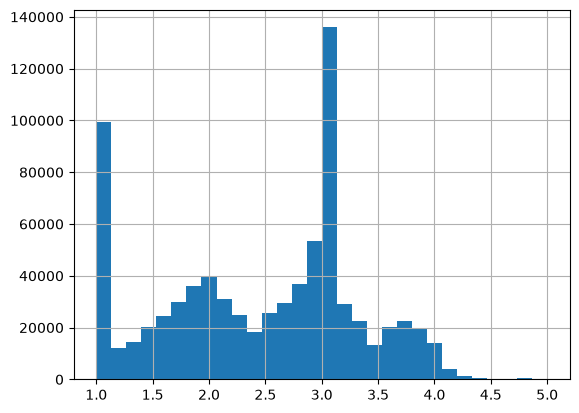

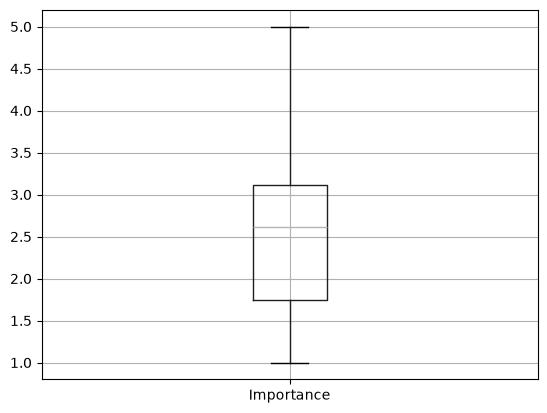

In [140]:
import matplotlib.pyplot as plt

dfMerged['Importance'].hist(bins=30)
plt.show()

dfMerged[['Importance']].boxplot()
plt.show()

In [141]:
col = 'Importance'
q1, q3 = dfMerged[col].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = dfMerged[(dfMerged[col] < q1 - 1.5*iqr) | (dfMerged[col] > q3 + 1.5*iqr)]
print(len(outliers), "outliers")

0 outliers


# normaize 

In [142]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Fix Skewness using a Log Transformation (+1 avoids errors if there are 0s)
# This compresses the massive 8651 range down to a tight, normal distribution curve
dfMerged['Tech Tool Used in Skill'] = np.log1p(dfMerged['Tech Tool Used in Skill'])

# 2. Select the columns that need normalization
# We EXCLUDE one-hot encoded columns (Hot Technology_Y/N) because binary columns shouldn't be scaled!
numeric_cols = [
    
    'Importance'
]

# 3. Apply Standard Scaling (Z-score normalization)
scaler = StandardScaler()
dfMerged[numeric_cols] = scaler.fit_transform(dfMerged[numeric_cols])

# Preview your scaled, unskewed feature data frame
dfMerged.head()


,O*NET-SOC Code,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,11-1011.00,0,0.0,0,1,0,0,1.914776
1,11-1011.00,0,0.0,0,1,0,1,2.064546
2,11-1011.00,0,0.0,0,1,0,2,1.776527
3,11-1011.00,0,0.0,0,1,0,3,1.914776
4,11-1011.00,0,0.0,0,1,0,4,1.062238


In [143]:
dfMerged.describe()

,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
count,779850.000000,779850.000000,779850.000000,779850.000000,779850.000000,779850.000000,7.798500e+05
mean,289.797173,6.095309,26.487882,0.365840,0.076842,12.000000,-1.679390e-16
std,234.650716,2.061499,23.135220,0.481665,0.266340,7.211107,1.000001e+00
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.679707e+00
25%,111.000000,4.304065,12.000000,0.000000,0.000000,6.000000,-8.156489e-01
50%,203.000000,5.932245,19.000000,0.000000,0.000000,12.000000,1.866589e-01
75%,440.000000,8.057377,36.000000,1.000000,0.000000,18.000000,7.626979e-01
max,909.000000,9.065546,133.000000,1.000000,1.000000,24.000000,2.928604e+00


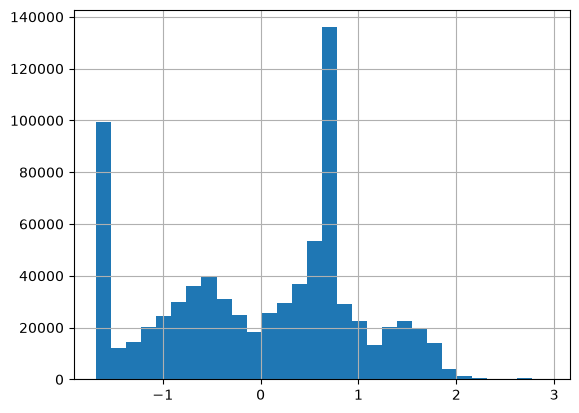

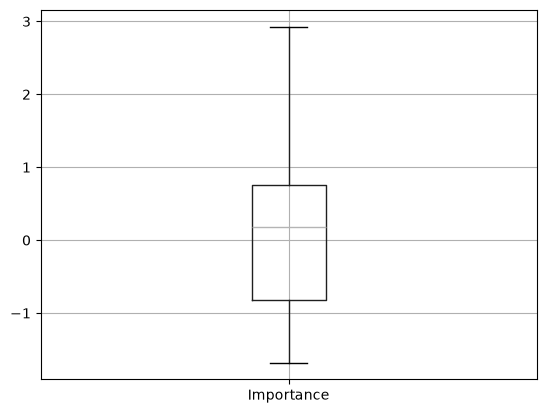

In [144]:
import matplotlib.pyplot as plt

dfMerged['Importance'].hist(bins=30)
plt.show()

dfMerged[['Importance']].boxplot()
plt.show()

# Cleaned O*NET-SOC Code

In [145]:
dfMerged["O*NET-SOC_clean"] = (
    dfMerged["O*NET-SOC Code"]
    .astype(str)
    .str.split(".").str[0]           # cut the period and everything after it
    .str.replace("-", "", regex=False)  # remove the dash
)



In [146]:
col = dfMerged.pop("O*NET-SOC_clean")
dfMerged.insert(dfMerged.columns.get_loc("Title"), "O*NET-SOC_clean", col)

In [147]:
dfMerged = dfMerged.drop(columns=["O*NET-SOC Code"])

In [148]:
dfMerged.head()

,O*NET-SOC_clean,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,111011,0,0.0,0,1,0,0,1.914776
1,111011,0,0.0,0,1,0,1,2.064546
2,111011,0,0.0,0,1,0,2,1.776527
3,111011,0,0.0,0,1,0,3,1.914776
4,111011,0,0.0,0,1,0,4,1.062238


# Compartmentalize clean datasheet from processed

In [149]:
output_path = Path("../data/processed/O-Net_data_cleaned.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

dfMerged.to_csv(output_path, index=False)

print(f"Saved cleaned dataset to: {output_path}")
print("Final shape:", dfMerged.shape)

Saved cleaned dataset to: ../data/processed/O-Net_data_cleaned.csv
Final shape: (779850, 8)


# Cleaing Header Titles

In [150]:
dfMerged.columns = (
    dfMerged.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

dfMerged.columns.tolist()

['o_net_soc_clean',
 'title',
 'tech_tool_used_in_skill',
 'software_or_tech_skills',
 'hot_technology',
 'in_demand',
 'transferable_or_soft_skills',
 'importance']

In [151]:
#from sklearn.preprocessing import MinMaxScaler, StandardScaler



#1. Min-Max Scaling (scales to 0-1 range) -> use if neural network 
#numeric_cols = ['Importance']  # replace with your real column names
#scaler = MinMaxScaler()
#dfMerged[numeric_cols] = scaler.fit_transform(dfMerged[numeric_cols])

# 2. Standardization (Z-Score) - use linear regression
#scaler = StandardScaler()
#dfMerged[numeric_cols] = scaler.fit_transform(dfMerged[numeric_cols])

# balance

In [152]:
# 1. Define 'y' as the column you want to predict (e.g., 'is_fraud' or 'status')
#y = dfMerged['In Demand_num']  # Replace with your actual target column name

# 2. Define 'X' as everything EXCEPT that target column
#X = dfMerged.drop(columns=['In Demand_num'])

# 3. Now you can safely run your RandomOverSampler code!
#from imblearn.over_sampling import RandomOverSampler

#ros = RandomOverSampler(random_state=42)
#X_balanced, y_balanced = ros.fit_resample(X, y)

In [153]:
#from imblearn.over_sampling import RandomOverSampler

#ros = RandomOverSampler(random_state=42)
#X_balanced, y_balanced = ros.fit_resample(X, y)



# starting to create visualization -> do later

In [154]:
# can't use cause of format in o*net code -> code in cell DOESN'T work

#corrs_matrix = round(dfMerged.corr(), 5)
#corrs_matrix 

In [155]:
#dfMerged["Hot Technology_num"] = (dfMerged["Hot Technology"] == "Y").astype(int)
#dfMerged["In Demand_num"] = (dfMerged["In Demand"] == "Y").astype(int)

In [156]:
#corrs_matrix = round(dfMerged.corr(numeric_only=True), 5)
#corrs_matrix

In [157]:
#corrs = corrs_matrix['Importance']
#corrs

In [158]:
#corrs_sorted = corrs.sort_values(ascending=False)
#corrs_sorted

In [159]:
#df_corrs = pd.DataFrame({'Importance': dfMerged['Importance'], 'In Demand': dfMerged['In Demand_num'], 'Hot Technology_num': dfMerged['Hot Technology_num']})

In [160]:
# sns.pairplot(data = df_corrs, kind = 'hist', corner = True)

In [161]:
#sns.pairplot(data = df_corrs, kind = 'kde', corner = True)